# K-Means — Agrupamiento de series de cultivos (EVA)

**Inteligencia Artificial I — Grupo C2, 2026-2**

Modelo no supervisado: **K-Means**. Agrupa las series (`municipio` + `cultivo`) según su comportamiento histórico en el periodo de entrenamiento **2007–2022**.

| Fase | Qué hace |
|---|---|
| 1 | Limpieza de datos (misma base que la fase supervisada) |
| 2 | Pipeline de series: construcción de 4 features por serie, filtro ($\ge 3$ años) y escalado (`StandardScaler`) |
| 3 | Selección del hiperparámetro **k** mediante Método del Codo, Silhouette y Davies-Bouldin |
| 4 | Entrenamiento del modelo final: métricas internas y perfil de cada cluster en unidades reales |
| 5 | Gráficas estandarizadas para interpretación y comparación con Agglomerative y DBSCAN |
| 6 | Exportación de resultados (`clusters_KMeans.csv`, `metricas_KMeans.csv`, `perfiles_KMeans.csv`) |
| 7 | Puente con la fase supervisada: evaluación del WAPE del SVR por cluster (prueba 2023–2025) |

In [ ]:
# =========================================================
# Librerias que vamos a usar
# =========================================================
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Estilo de las graficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["font.size"] = 11

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
AZUL = "#264653"
GRIS = "#bbbbbb"

# Para ver bien las tablas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

SEMILLA = 42
print("Librerias cargadas correctamente")

Librerias cargadas correctamente


## Fase 1 — Limpieza de datos

Es la misma limpieza de la fase supervisada. Deja la tabla `datos` con una fila por `municipio` + `cultivo` + `estado_fisico` + `anio`.

In [ ]:
# =====================================================================
# LIMPIEZA DEFINITIVA DE LOS ARCHIVOS EVA (2007-2018 y 2019-2025)
# Resultado: la tabla "datos" con UNA fila por municipio + cultivo +
# estado fisico + anio, lista para entrenar los modelos.
# =====================================================================

# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto: los numeros vienen en formato colombiano
# ("1.247.206,27") y los codigos DANE tienen ceros a la izquierda ("05001").
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
# =========================================================
print("PASO 2: Dejar solo las columnas necesarias, con el mismo nombre")

eva_viejo.columns = [" ".join(nombre.split()) for nombre in eva_viejo.columns]
eva_nuevo.columns = [" ".join(nombre.split()) for nombre in eva_nuevo.columns]

nombres_nuevo = {
    "Código Dane departamento":  "cod_dep",
    "Departamento":              "departamento",
    "Código Dane municipio":     "cod_mun",
    "Municipio":                 "municipio",
    "Grupo cultivo":             "grupo",
    "Cultivo":                   "cultivo",
    "Desagregación cultivo":     "desagregacion",
    "Año":                       "anio",
    "Periodo":                   "periodo",
    "Área sembrada":             "area_sembrada",
    "Área cosechada":            "area_cosechada",
    "Producción":                "produccion",
    "Ciclo del cultivo":         "ciclo",
    "Estado físico del cultivo": "estado_fisico",
}
nombres_viejo = {
    "CÓD. DEP.":                                     "cod_dep",
    "DEPARTAMENTO":                                  "departamento",
    "CÓD. MUN.":                                     "cod_mun",
    "MUNICIPIO":                                     "municipio",
    "GRUPO DE CULTIVO":                              "grupo",
    "CULTIVO":                                       "cultivo",
    "DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO": "desagregacion",
    "AÑO":                                           "anio",
    "PERIODO":                                       "periodo",
    "Área Sembrada (ha)":                            "area_sembrada",
    "Área Cosechada (ha)":                           "area_cosechada",
    "Producción (t)":                                "produccion",
    "CICLO DE CULTIVO":                              "ciclo",
    "ESTADO FISICO PRODUCCION":                      "estado_fisico",
}
COLUMNAS = list(nombres_nuevo.values())
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)[COLUMNAS].copy()
eva_viejo = eva_viejo.rename(columns=nombres_viejo)[COLUMNAS].copy()

print("Columnas que se conservan:", COLUMNAS)
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Convertir los numeros y los codigos DANE
# =========================================================
print("PASO 3: Convertir los numeros y los codigos DANE")

def convertir_a_numero(columna):
    texto = columna.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

for df in (eva_viejo, eva_nuevo):
    for columna in ["anio", "area_sembrada", "area_cosechada", "produccion"]:
        df[columna] = convertir_a_numero(df[columna])
    df["anio"] = df["anio"].astype(int)
    df["cod_dep"] = df["cod_dep"].str.replace(".", "", regex=False).str.zfill(2)
    df["cod_mun"] = df["cod_mun"].str.replace(".", "", regex=False).str.zfill(5)

for nombre, df in [("2007-2018", eva_viejo), ("2019-2025", eva_nuevo)]:
    numeros = df[["area_sembrada", "area_cosechada", "produccion"]]
    assert numeros.notna().all().all(), "Hay numeros que no se pudieron convertir en " + nombre
    assert (numeros >= 0).all().all(), "Hay numeros negativos en " + nombre
    assert (df["cod_mun"].str[:2] == df["cod_dep"]).all(), "Codigos inconsistentes en " + nombre

print("PASO 3: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto.str.replace(r"\s+", " ", regex=True)

for df in (eva_viejo, eva_nuevo):
    for columna in ["departamento", "municipio", "grupo", "cultivo",
                    "desagregacion", "ciclo", "estado_fisico"]:
        df[columna] = limpiar_texto(df[columna])

print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 5: Estandarizar los nombres de cultivo y de estado fisico
# =========================================================
print("PASO 5: Estandarizar los nombres de cultivo y de estado fisico")

es_cana = eva_nuevo["cultivo"] == "CANA"
eva_nuevo.loc[es_cana, "cultivo"] = eva_nuevo.loc[es_cana, "desagregacion"]
eva_nuevo["cultivo"] = eva_nuevo["cultivo"].replace({"CANA DE AZUCAR": "CANA AZUCARERA",
                                                     "ESTEVIA": "STEVIA"})

cultivos_equivalentes = {
    "DURAZNO":     "DURAZNO O ALBARICOQUE",
    "AGRAZ":       "AGRAZ - MORTINO",
    "PEPA DE PAN": "ARBOL DE PAN O PEPA DEL PAN",
    "PAPAYUELA":   "PAPAYUELA -BABACO",
    "CURCUMA":     "CURCUMA O AZAFRAN",
    "RUBA":        "ULLUCO",
    "GULUPA":      "GULUPA O CHOLUPA",
    "CHOLUPA":     "GULUPA O CHOLUPA",
    "CALABACIN":   "CALABACIN, CALABAZA",
    "CALABAZA":    "CALABACIN, CALABAZA",
    "MALANGA":     "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
    "BORE":        "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
}
eva_viejo["cultivo"] = eva_viejo["cultivo"].replace(cultivos_equivalentes)

estados_equivalentes = {
    "FRUTO FRESCO":       "EN FRESCO",
    "HORTALIZA FRESCA":   "EN FRESCO",
    "TUBERCULO FRESCO":   "EN FRESCO",
    "HOJA FRESCA":        "EN FRESCO",
    "LEGUMINOSA FRESCA":  "EN FRESCO",
    "PADDY VERDE":        "PADDY O CASCARA VERDE",
    "SEMILLA":            "ALGODON SEMILLA",
    "CANA PARA MOLIENDA": "CANA O VERDE",
}
eva_viejo["estado_fisico"] = eva_viejo["estado_fisico"].replace(estados_equivalentes)

print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
# =========================================================
print("PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos")

cultivos_comunes = set(eva_viejo["cultivo"]) & set(eva_nuevo["cultivo"])
eliminados = (pd.concat([eva_viejo, eva_nuevo])
                .loc[lambda df: ~df["cultivo"].isin(cultivos_comunes)]
                .groupby("cultivo")["area_cosechada"].sum()
                .sort_values(ascending=False))
print("Cultivos que estan en un solo archivo (se eliminan):", len(eliminados))

eva_viejo = eva_viejo[eva_viejo["cultivo"].isin(cultivos_comunes)].copy()
eva_nuevo = eva_nuevo[eva_nuevo["cultivo"].isin(cultivos_comunes)].copy()

catalogo = eva_nuevo.groupby("cultivo")[["grupo", "ciclo"]].first()
assert (eva_nuevo.groupby("cultivo")["grupo"].nunique() == 1).all()
assert (eva_nuevo.groupby("cultivo")["ciclo"].nunique() == 1).all()

eva_viejo["grupo"] = eva_viejo["cultivo"].map(catalogo["grupo"])
eva_viejo["ciclo"] = eva_viejo["cultivo"].map(catalogo["ciclo"])

print("Cultivos que quedan:", len(cultivos_comunes))
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018
# =========================================================
print("PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018")

eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"
datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

for codigo, nombre in [("cod_dep", "departamento"), ("cod_mun", "municipio")]:
    nombre_oficial = datos.sort_values("fuente").groupby(codigo)[nombre].last()
    datos[nombre] = datos[codigo].map(nombre_oficial)

datos = datos[~datos["anio"].isin([2006, 2018])]
print("Filas despues de unir:", len(datos))
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Pasar de semestres a anios (suma simple)
# =========================================================
print("PASO 8: Pasar de semestres a anios (suma simple)")

CLAVE = ["cod_mun", "cultivo", "estado_fisico", "anio"]
datos = (datos.groupby(CLAVE, as_index=False)
              .agg(fuente=("fuente", "first"),
                   cod_dep=("cod_dep", "first"),
                   departamento=("departamento", "first"),
                   municipio=("municipio", "first"),
                   grupo=("grupo", "first"),
                   ciclo=("ciclo", "first"),
                   area_sembrada=("area_sembrada", "sum"),
                   area_cosechada=("area_cosechada", "sum"),
                   produccion=("produccion", "sum")))

datos["rendimiento"] = np.where(datos["area_cosechada"] > 0,
                                datos["produccion"] / datos["area_cosechada"], np.nan)

print("Filas anuales:", len(datos))
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Regla de arrastre (sin tolerancia) y consistencia
# =========================================================
print("PASO 9: Regla de arrastre (sin tolerancia) y consistencia")

datos = datos.sort_values(CLAVE).reset_index(drop=True)
serie = datos.groupby(["cod_mun", "cultivo", "estado_fisico"])
sembrada_ant = serie["area_sembrada"].shift(1)
cosechada_ant = serie["area_cosechada"].shift(1)
anio_ant = serie["anio"].shift(1)

hay_arrastre = (datos["anio"] - anio_ant == 1) & (datos["ciclo"] == "TRANSITORIO")
datos["area_pendiente_anterior"] = np.where(hay_arrastre,
                                            (sembrada_ant - cosechada_ant).clip(lower=0), 0.0)
area_disponible = datos["area_sembrada"] + datos["area_pendiente_anterior"]

regla_arrastre = datos["area_cosechada"] > area_disponible
regla_produccion = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)
sin_area = area_disponible == 0

datos = datos[~(regla_arrastre | regla_produccion | sin_area)].reset_index(drop=True)
print("Filas que quedan:", len(datos))
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 10: Agregar la altura de cada municipio (msnm)
# =========================================================
print("PASO 10: Agregar la altura de cada municipio (msnm)")

ARCHIVO_ALTURA = RUTA + "PANEL_CARACTERISTICAS_GENERALES_2021.csv"
altura = pd.read_csv(ARCHIVO_ALTURA, usecols=["codmpio", "altura"], encoding="latin-1")
altura = altura.dropna(subset=["altura"]).drop_duplicates(subset="codmpio")
altura["cod_mun"] = altura["codmpio"].astype(int).astype(str).str.zfill(5)
altura = altura.rename(columns={"altura": "altura_msnm"})[["cod_mun", "altura_msnm"]]

altura_manual = pd.DataFrame({
    "cod_mun":     ["27493"],
    "altura_msnm": [105],
})
altura = pd.concat([altura, altura_manual], ignore_index=True)
datos = datos.merge(altura, on="cod_mun", how="left")

print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 11: Revision final y orden de columnas
# =========================================================
print("PASO 11: Revision final y orden de columnas")

assert not datos.duplicated(CLAVE).any(), "Hay filas repetidas en la clave"

COLUMNAS_FINALES = ["anio", "fuente", "cod_dep", "departamento", "cod_mun", "municipio",
                    "altura_msnm", "grupo", "cultivo", "ciclo", "estado_fisico",
                    "area_sembrada", "area_pendiente_anterior", "area_cosechada",
                    "produccion", "rendimiento"]
datos = datos[COLUMNAS_FINALES]

print("Filas:", len(datos), "| Columnas:", datos.shape[1])
print("Anios:", sorted(datos["anio"].unique()))
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")
datos.head()

PASO 1: Cargar los dos archivos desde Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
Columnas que se conservan: ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'cultivo', 'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion', 'ciclo', 'estado_fisico']
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Convertir los numeros y los codigos DANE
PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes
PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Estandarizar los nombres de cultivo y de estado fisico
PASO 5: Ejecutado correctamente
------------

,anio,fuente,cod_dep,departamento,cod_mun,municipio,altura_msnm,grupo,cultivo,ciclo,estado_fisico,area_sembrada,area_pendiente_anterior,area_cosechada,produccion,rendimiento
0,2007,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.00,0.00,0.00,0.00,NaN
1,2008,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.00,0.00,0.00,0.00,NaN
2,2009,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,12.00,0.00,6.00,36.00,6.00
3,2010,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,16.00,0.00,10.00,60.00,6.00
4,2011,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,19.00,0.00,16.00,96.00,6.00


## Fase 2 — Pipeline de series

Aquí **no se agrupan filas, se agrupan series**. Una **serie** es un **municipio + cultivo** a lo largo de los años (sin `estado_fisico`, porque cambia entre los dos archivos EVA).

| Paso | Qué hace |
|---|---|
| S1 | Suma las áreas por municipio + cultivo + año y deja solo **2007–2022** (no se usan los años de prueba) |
| S2 | Resume cada serie en **4 features** y deja las series con **3 años o más** de registro |
| S3 | Escala las 4 features con `StandardScaler` (K-Means calcula distancias euclidianas) |

| Feature | Cómo se calcula | Qué dice de la serie |
|---|---|---|
| `log_area_media` | $\log(1 + \text{promedio del área disponible})$ | Qué tan grande es el cultivo en el municipio |
| `tasa_media` | $\text{total cosechado} / \text{total disponible}$ | Qué proporción logra cosechar normalmente |
| `desv_tasa` | $\text{desviación estándar de la tasa anual}$ | Qué tan estable es su cosecha en el tiempo |
| `cv_area` | $\text{desv. estándar área sembrada} / \text{promedio}$ | Qué tanto varía la superficie sembrada año a año |

`ciclo`, `grupo` y `departamento` **no entran al agrupamiento**: se reservan para interpretar los clusters después.

In [ ]:
# =========================================================
# PASO S1: Armar las series (municipio + cultivo) por anio
# =========================================================
print("PASO S1: Armar las series por anio")
ANIO_FIN = 2022          # solo 2007-2022: los anios de prueba (2023-2025) no se usan
MIN_ANIOS = 3            # una serie debe tener 3 anios o mas de registro

SERIE = ["cod_mun", "cultivo"]
AREAS = ["area_sembrada", "area_pendiente_anterior", "area_cosechada"]

# Una fila por municipio + cultivo + anio (se suman los estados fisicos)
anual = datos[datos["anio"] <= ANIO_FIN].groupby(SERIE + ["anio"], as_index=False)[AREAS].sum()

# Area que habia para cosechar y tasa de cosecha de cada anio
anual["area_disponible"] = anual["area_sembrada"] + anual["area_pendiente_anterior"]
anual["tasa"] = anual["area_cosechada"] / anual["area_disponible"]

print("Filas (municipio + cultivo + anio):", len(anual))
print("Series (municipio + cultivo):", anual.groupby(SERIE).ngroups)
print("PASO S1: Ejecutado correctamente")
print("-------------------------------")

PASO S1: Armar las series por anio
Filas (municipio + cultivo + anio): 192016
Series (municipio + cultivo): 21084
PASO S1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO S2: Resumir cada serie en 4 features y filtrar
# =========================================================
print("PASO S2: Resumir cada serie en 4 features")
FEATURES = ["log_area_media", "tasa_media", "desv_tasa", "cv_area"]

g = anual.groupby(SERIE)
series = pd.DataFrame({
    "anios": g["anio"].count(),                                     # anios con registro
    "area_media": g["area_disponible"].mean(),                      # hectareas promedio
    "tasa_media": g["area_cosechada"].sum() / g["area_disponible"].sum(),
    "desv_tasa": g["tasa"].std(),
    "cv_area": g["area_sembrada"].std() / g["area_sembrada"].mean(),
}).reset_index()
series["log_area_media"] = np.log1p(series["area_media"])

# Filtro: solo series con 3 anios o mas (sin limite de hectareas)
total = len(series)
series = series[series["anios"] >= MIN_ANIOS].reset_index(drop=True)

# Columnas para interpretar los clusters (NO entran al agrupamiento)
info = datos.drop_duplicates(SERIE)[SERIE + ["municipio", "departamento", "grupo", "ciclo"]]
series = series.merge(info, on=SERIE, how="left")

print("Series totales:", total, "| Series con", MIN_ANIOS, "anios o mas:", len(series))
print("Datos faltantes en las features:", int(series[FEATURES].isna().sum().sum()))
print()
print(series[FEATURES].describe().round(3).to_string())
print("PASO S2: Ejecutado correctamente")
print("-------------------------------")

PASO S2: Resumir cada serie en 4 features
Series totales: 21084 | Series con 3 anios o mas: 17336
Datos faltantes en las features: 0

       log_area_media  tasa_media  desv_tasa   cv_area
count       17,336.00   17,336.00  17,336.00 17,336.00
mean             3.83        0.82       0.17      0.50
std              1.80        0.15       0.12      0.32
min              0.03        0.00       0.00      0.00
25%              2.46        0.75       0.08      0.27
50%              3.59        0.86       0.15      0.45
75%              4.99        0.94       0.24      0.67
max             10.53        1.00       0.58      3.32
PASO S2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO S3: Escalar las features
# =========================================================
print("PASO S3: Escalar las features")
# K-Means usa distancia euclidiana: todas las features deben pesar igual
X = StandardScaler().fit_transform(series[FEATURES])

print("Matriz para agrupar:", X.shape[0], "series x", X.shape[1], "features")
print("PASO S3: Ejecutado correctamente")
print("-------------------------------")

PASO S3: Escalar las features
Matriz para agrupar: 17336 series x 4 features
PASO S3: Ejecutado correctamente
-------------------------------


## Fase 3 — Elegir el hiperparámetro k (K-Means)

K-Means requiere definir de antemano **cuántos clusters (`k`)** formar. Se evalúa $k \in [2, 10]$ usando tres criterios complementarios:

- **Método del codo (Inercia / WCSS):** suma de distancias al cuadrado de cada serie al centroide de su cluster. Se busca el punto de inflexión (*codo*) donde agregar más clusters aporta poca reducción adicional.
- **Silhouette:** mide cohesión interna vs. separación externa ($[-1, 1]$). Valores más **altos** indican clusters mejor definidos.
- **Davies-Bouldin:** mide la similitud promedio entre cada cluster y su vecino más cercano. Valores más **bajos** son mejores.

> **Instrucción:** Ejecuta **H1**, revisa las gráficas y la tabla, y ajusta `K` en **H2** si otro valor muestra un mejor equilibrio entre codo y Silhouette.

PASO H1: Evaluacion de k = 2..10 para K-Means
k = 2 listo
k = 3 listo
k = 4 listo
k = 5 listo
k = 6 listo
k = 7 listo
k = 8 listo
k = 9 listo
k = 10 listo


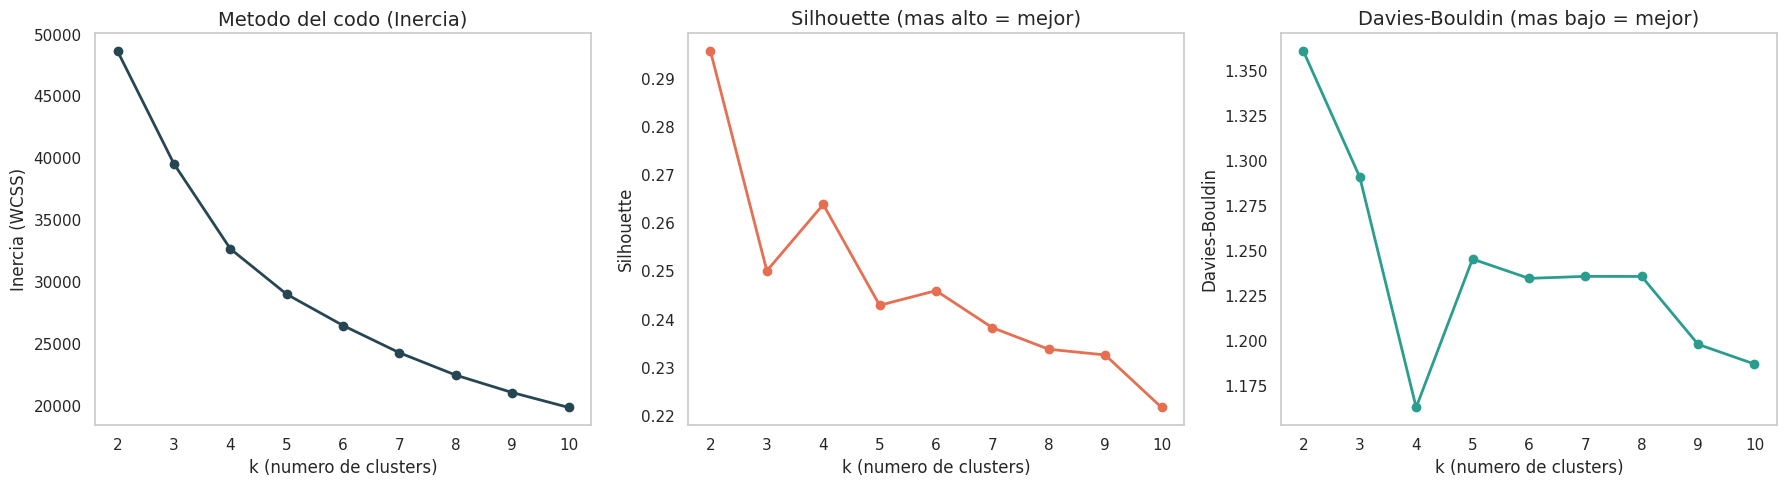

 k   inercia  silhouette  davies_bouldin
 2 48,659.71        0.30            1.36
 3 39,555.00        0.25            1.29
 4 32,688.07        0.26            1.16
 5 29,014.42        0.24            1.25
 6 26,488.31        0.25            1.24
 7 24,285.83        0.24            1.24
 8 22,477.36        0.23            1.24
 9 21,073.16        0.23            1.20
10 19,868.04        0.22            1.19
PASO H1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO H1: Metodo del codo, Silhouette y Davies-Bouldin
# =========================================================
print("PASO H1: Evaluacion de k = 2..10 para K-Means")

VALORES_K = range(2, 11)
pruebas = []
for k in VALORES_K:
    modelo_tmp = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    pruebas.append({
        "k": k,
        "inercia": modelo_tmp.inertia_,
        "silhouette": silhouette_score(X, modelo_tmp.labels_),
        "davies_bouldin": davies_bouldin_score(X, modelo_tmp.labels_),
    })
    print(f"k = {k} listo")
pruebas = pd.DataFrame(pruebas)

# Grafica de 1 fila por 3 columnas sin cuadricula
figura, ejes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Codo (Inercia)
ejes[0].plot(pruebas["k"], pruebas["inercia"], marker="o", linewidth=2, color=AZUL)
ejes[0].set_title("Metodo del codo (Inercia)")
ejes[0].set_xlabel("k (numero de clusters)")
ejes[0].set_ylabel("Inercia (WCSS)")

# 2. Silhouette (mas alto = mejor)
ejes[1].plot(pruebas["k"], pruebas["silhouette"], marker="o", linewidth=2, color=NARANJA)
ejes[1].set_title("Silhouette (mas alto = mejor)")
ejes[1].set_xlabel("k (numero de clusters)")
ejes[1].set_ylabel("Silhouette")

# 3. Davies-Bouldin (mas bajo = mejor)
ejes[2].plot(pruebas["k"], pruebas["davies_bouldin"], marker="o", linewidth=2, color=VERDE)
ejes[2].set_title("Davies-Bouldin (mas bajo = mejor)")
ejes[2].set_xlabel("k (numero de clusters)")
ejes[2].set_ylabel("Davies-Bouldin")

for ax in ejes:
    ax.set_xticks(list(VALORES_K))
    ax.grid(False)

plt.tight_layout()
plt.show()

print(pruebas.round(3).to_string(index=False))
print("PASO H1: Ejecutado correctamente")
print("-------------------------------")

In [ ]:
# =========================================================
# PASO H2: Hiperparametro elegido  (EDITAR AQUI SI CAMBIA K)
# =========================================================
print("PASO H2: Hiperparametro elegido")

K = 4               # numero de clusters elegido tras revisar el codo y silhouette en H1

print("k seleccionado =", K)
print("PASO H2: Ejecutado correctamente")
print("-------------------------------")

PASO H2: Hiperparametro elegido
k seleccionado = 4
PASO H2: Ejecutado correctamente
-------------------------------


## Modelo final (K-Means)

Se entrena el modelo definitivo con el valor de `K` fijado en **H2** (`n_init=10` inicializaciones con `random_state=42`). Si cambias `K`, vuelve a ejecutar desde **H2** hacia abajo.

In [ ]:
# =========================================================
# PASO M1: Entrenar el modelo final K-Means
# =========================================================
print("PASO M1: Entrenar K-Means")
NOMBRE_MODELO = "KMeans"
HIPERPARAMETROS = "k=" + str(K)

inicio = time.time()
modelo = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X)
etiquetas = modelo.labels_
segundos = round(time.time() - inicio, 2)

print("Modelo:", NOMBRE_MODELO, "| Hiperparametros:", HIPERPARAMETROS, "| Tiempo:", segundos, "s")
print("PASO M1: Ejecutado correctamente")
print("-------------------------------")

PASO M1: Entrenar K-Means
Modelo: KMeans | Hiperparametros: k=4 | Tiempo: 0.19 s
PASO M1: Ejecutado correctamente
-------------------------------


## Fase 4 — Resultados del modelo

**Métricas** (en K-Means todas las series pertenecen a un cluster, por lo que `ruido_% = 0.0`):

| Métrica | Qué mide | Mejor si |
|---|---|---|
| Inercia (Codo) | Suma de las distancias al cuadrado de cada serie a su centroide | Más bajo (buscando el punto de quiebre o "codo")
| Silhouette | Qué tan cerca está cada serie de su cluster frente al cluster vecino (−1 a 1) | Más alto |
| Davies-Bouldin | Qué tan parecidos son los clusters entre sí | Más bajo |


Los clusters se renumeran por tamaño: **el Cluster 0 es el más grande**.

In [ ]:
# =========================================================
# PASO R1: Metricas del agrupamiento
# =========================================================
print("PASO R1: Metricas del agrupamiento")

# Renumerar: 0 = cluster mas grande
conteo = pd.Series(etiquetas[etiquetas >= 0]).value_counts()
nuevo = {viejo: i for i, viejo in enumerate(conteo.index)}
nuevo[-1] = -1
series["cluster"] = [nuevo[e] for e in etiquetas]

sin_ruido = (series["cluster"] >= 0).values
n_clusters = series.loc[sin_ruido, "cluster"].nunique()
tamanos = series.loc[sin_ruido, "cluster"].value_counts()

metricas_modelo = {
    "modelo": NOMBRE_MODELO,
    "hiperparametros": HIPERPARAMETROS,
    "series": len(series),
    "n_clusters": n_clusters,
    "ruido_%": (~sin_ruido).mean() * 100,
    "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan,
    "cluster_mas_grande": tamanos.max(),
    "cluster_mas_pequeno": tamanos.min(),
    "segundos": segundos,
}
if n_clusters >= 2:
    metricas_modelo["silhouette"] = silhouette_score(X[sin_ruido], series.loc[sin_ruido, "cluster"])
    metricas_modelo["davies_bouldin"] = davies_bouldin_score(X[sin_ruido], series.loc[sin_ruido, "cluster"])
    metricas_modelo["calinski_harabasz"] = calinski_harabasz_score(X[sin_ruido], series.loc[sin_ruido, "cluster"])

for nombre, valor in metricas_modelo.items():
    print(nombre.ljust(20), ":", round(valor, 3) if isinstance(valor, float) else valor)
print("PASO R1: Ejecutado correctamente")
print("-------------------------------")

PASO R1: Metricas del agrupamiento
modelo               : KMeans
hiperparametros      : k=4
series               : 17336
n_clusters           : 4
ruido_%              : 0.0
silhouette           : 0.264
davies_bouldin       : 1.163
calinski_harabasz    : 6478.653
cluster_mas_grande   : 5872
cluster_mas_pequeno  : 3111
segundos             : 0.21
PASO R1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO R2: Perfil de cada cluster (en unidades reales)
# =========================================================
print("PASO R2: Perfil de cada cluster")

def nombre_cluster(c):
    return "Ruido" if c == -1 else "Cluster " + str(c)

g = series.groupby("cluster")
perfiles = pd.DataFrame({
    "series": g.size(),
    "% de las series": g.size() / len(series) * 100,
    "% del area": g["area_media"].sum() / series["area_media"].sum() * 100,
    "area tipica (ha)": np.expm1(g["log_area_media"].mean()),
    "tasa de cosecha (%)": g["tasa_media"].mean() * 100,
    "desv. de la tasa (puntos)": g["desv_tasa"].mean() * 100,
    "cv del area": g["cv_area"].mean(),
    "% permanentes": g["ciclo"].apply(lambda s: (s == "PERMANENTE").mean() * 100),
})
perfiles.index = [nombre_cluster(c) for c in perfiles.index]
print(perfiles.round(1).to_string())

print()
print("Los 3 cultivos con mas series en cada cluster:")
for c, tabla in series.groupby("cluster"):
    print(" ", nombre_cluster(c).ljust(10), "->", ", ".join(tabla["cultivo"].value_counts().head(3).index))
print("PASO R2: Ejecutado correctamente")
print("-------------------------------")

PASO R2: Perfil de cada cluster
           series  % de las series  % del area  area tipica (ha)  tasa de cosecha (%)  desv. de la tasa (puntos)  cv del area  % permanentes
Cluster 0    5872            33.90        2.50             14.10                91.30                       9.50         0.40          44.10
Cluster 1    4188            24.20        5.00             19.80                63.90                      32.90         0.50          78.50
Cluster 2    4165            24.00       86.10            459.00                86.80                      12.40         0.30          57.40
Cluster 3    3111            17.90        6.50             49.40                85.30                      16.70         1.00          38.60

Los 3 cultivos con mas series en cada cluster:
  Cluster 0  -> TOMATE, FRIJOL, YUCA
  Cluster 1  -> AGUACATE, CACAO, LULO
  Cluster 2  -> CAFE, PLATANO, MAIZ
  Cluster 3  -> MAIZ, FRIJOL, YUCA
PASO R2: Ejecutado correctamente
-------------------------------


## Fase 5 — Gráficas para interpretar y comparar

Las mismas 3 gráficas estandarizadas del equipo para comparar **K-Means**, **Agglomerative** y **DBSCAN**:

1. **Mapa de las series:** tamaño (`log_area_media`) contra tasa de cosecha media (`tasa_media`), coloreado por cluster.
2. **Perfil de los clusters (Heatmap):** rojo = por encima del promedio general, azul = por debajo. El número dentro de la celda muestra el valor en unidades reales.
3. **Permanentes y transitorios por cluster:** validación externa usando `ciclo` (variable que no participó en el entrenamiento).

PASO G1: Mapa de las series


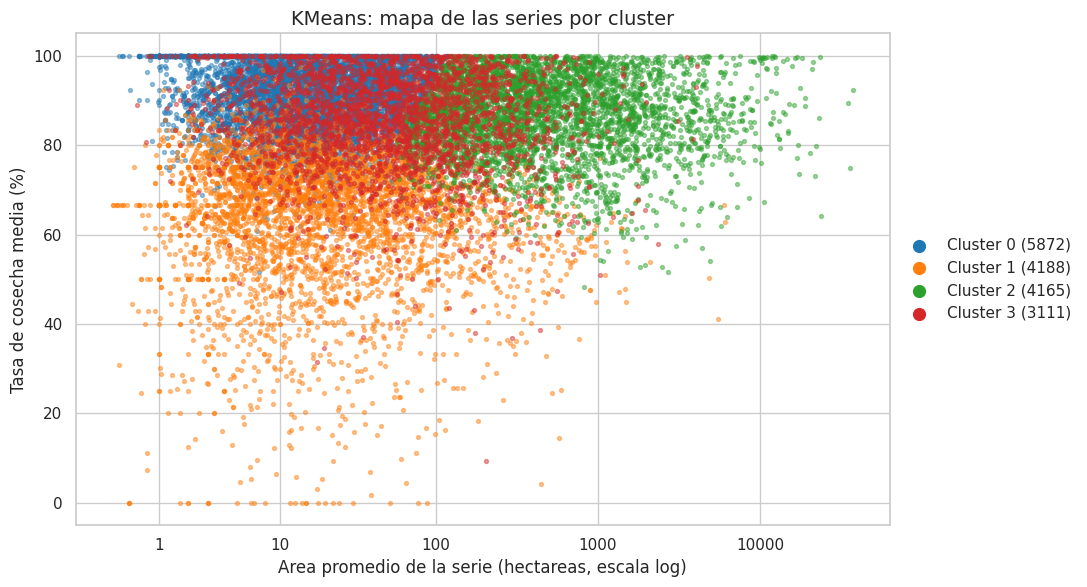

PASO G1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO G1: Mapa de las series (tamanio vs tasa de cosecha)
# =========================================================
print("PASO G1: Mapa de las series")
clusters = sorted(c for c in series["cluster"].unique() if c >= 0)
paleta = sns.color_palette("tab10", max(len(clusters), 1))
COLOR_CLUSTER = {c: paleta[i % 10] for i, c in enumerate(clusters)}
COLOR_CLUSTER[-1] = GRIS

plt.figure(figsize=(11, 6))
for c in [-1] + clusters:
    t = series[series["cluster"] == c]
    if len(t) > 0:
        plt.scatter(t["log_area_media"], t["tasa_media"] * 100, s=8, alpha=0.45,
                    color=COLOR_CLUSTER[c], label=nombre_cluster(c) + " (" + str(len(t)) + ")")
hectareas = [1, 10, 100, 1000, 10000]
plt.xticks(np.log1p(hectareas), [str(h) for h in hectareas])
plt.xlabel("Area promedio de la serie (hectareas, escala log)")
plt.ylabel("Tasa de cosecha media (%)")
plt.title(NOMBRE_MODELO + ": mapa de las series por cluster")
leyenda = plt.legend(frameon=False, markerscale=3, loc="center left", bbox_to_anchor=(1, 0.5))
for marca in leyenda.legend_handles:
    marca.set_alpha(1)
plt.tight_layout()
plt.show()
print("PASO G1: Ejecutado correctamente")
print("-------------------------------")

PASO G2: Perfil de los clusters


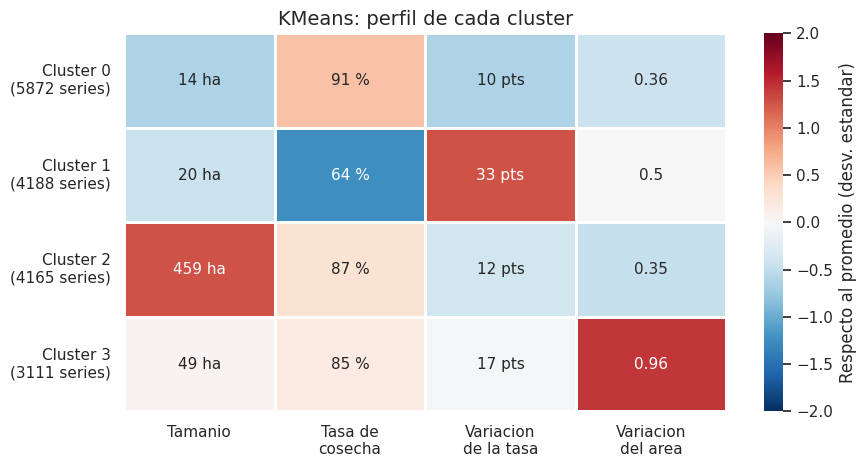

PASO G2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO G2: Perfil de los clusters
# =========================================================
print("PASO G2: Perfil de los clusters")
TITULOS = ["Tamanio", "Tasa de\ncosecha", "Variacion\nde la tasa", "Variacion\ndel area"]

# Color: promedio de cada feature ESCALADA (0 = promedio de todas las series)
escaladas = pd.DataFrame(X, columns=FEATURES).groupby(series["cluster"].values).mean()
# Texto: el valor real de cada feature
medias = series.groupby("cluster")[FEATURES].mean()
texto = pd.DataFrame({
    "Tamanio": np.expm1(medias["log_area_media"]).round(0).astype(int).astype(str) + " ha",
    "Tasa de cosecha": (medias["tasa_media"] * 100).round(0).astype(int).astype(str) + " %",
    "Variacion de la tasa": (medias["desv_tasa"] * 100).round(0).astype(int).astype(str) + " pts",
    "Variacion del area": medias["cv_area"].round(2).astype(str),
})
filas = [nombre_cluster(c) + "\n(" + str(n) + " series)" for c, n in series.groupby("cluster").size().items()]

plt.figure(figsize=(9, 1.2 + 0.9 * len(filas)))
sns.heatmap(escaladas.values, annot=texto.values, fmt="", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            xticklabels=TITULOS, yticklabels=filas, linewidths=1, linecolor="white",
            cbar_kws={"label": "Respecto al promedio (desv. estandar)"})
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.title(NOMBRE_MODELO + ": perfil de cada cluster")
plt.tight_layout()
plt.show()
print("PASO G2: Ejecutado correctamente")
print("-------------------------------")

PASO G3: Permanentes y transitorios en cada cluster


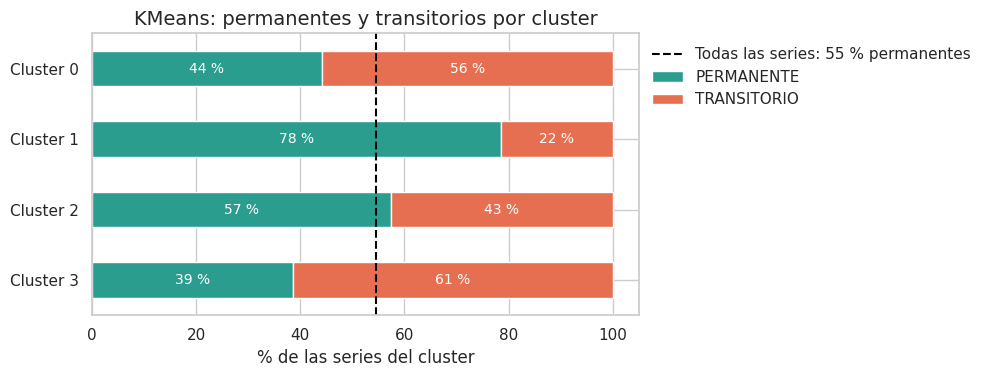

ciclo      PERMANENTE  TRANSITORIO
Cluster 0       44.10        55.90
Cluster 1       78.50        21.50
Cluster 2       57.40        42.60
Cluster 3       38.60        61.40
PASO G3: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO G3: Permanentes y transitorios en cada cluster
# =========================================================
print("PASO G3: Permanentes y transitorios en cada cluster")
ciclos = pd.crosstab(series["cluster"], series["ciclo"], normalize="index") * 100
ciclos.index = [nombre_cluster(c) for c in ciclos.index]

ax = ciclos.plot(kind="barh", stacked=True, color=[VERDE, NARANJA], figsize=(10, 1.5 + 0.6 * len(ciclos)))
for barras in ax.containers:
    textos = [str(round(v)) + " %" if v >= 5 else "" for v in barras.datavalues]
    ax.bar_label(barras, labels=textos, label_type="center", color="white", fontsize=10)
general = (series["ciclo"] == "PERMANENTE").mean() * 100
ax.axvline(general, color="black", linestyle="--", linewidth=1.5,
           label="Todas las series: " + str(round(general)) + " % permanentes")
ax.invert_yaxis()
ax.set_xlabel("% de las series del cluster")
ax.set_title(NOMBRE_MODELO + ": permanentes y transitorios por cluster")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print(ciclos.round(1).to_string())
print("PASO G3: Ejecutado correctamente")
print("-------------------------------")

## Fase 6 — Guardar los resultados

Se guardan en `EVA/Resultados_clustering/`:

| Archivo | Contenido |
|---|---|
| `clusters_KMeans.csv` | Una fila por serie: `cod_mun`, `cultivo`, sus features y su **cluster**. Sirve para cruzar con `predicciones_SVR.csv` |
| `metricas_KMeans.csv` | Una fila con los hiperparámetros y las métricas, para la tabla comparativa de los 3 modelos |
| `perfiles_KMeans.csv` | El perfil estadístico de cada cluster |

In [ ]:
# =========================================================
# PASO E1: Guardar los archivos del modelo
# =========================================================
print("PASO E1: Guardar los archivos del modelo")
RUTA_CLUSTERING = RUTA + "Resultados_clustering/"
os.makedirs(RUTA_CLUSTERING, exist_ok=True)

columnas = ["cod_mun", "cultivo", "municipio", "departamento", "grupo", "ciclo", "anios",
            "area_media"] + FEATURES + ["cluster"]
salida = series[columnas].copy()
salida["modelo"] = NOMBRE_MODELO
salida.to_csv(RUTA_CLUSTERING + "clusters_" + NOMBRE_MODELO + ".csv", index=False, encoding="utf-8-sig")
pd.DataFrame([metricas_modelo]).to_csv(RUTA_CLUSTERING + "metricas_" + NOMBRE_MODELO + ".csv", index=False)
perfiles.to_csv(RUTA_CLUSTERING + "perfiles_" + NOMBRE_MODELO + ".csv", encoding="utf-8-sig")

print("Guardados en", RUTA_CLUSTERING)
print("  clusters_" + NOMBRE_MODELO + ".csv |", len(salida), "series")
print("  metricas_" + NOMBRE_MODELO + ".csv")
print("  perfiles_" + NOMBRE_MODELO + ".csv")
print("PASO E1: Ejecutado correctamente")
print("-------------------------------")

PASO E1: Guardar los archivos del modelo
Guardados en /content/drive/MyDrive/EVA/Resultados_clustering/
  clusters_KMeans.csv | 17336 series
  metricas_KMeans.csv
  perfiles_KMeans.csv
PASO E1: Ejecutado correctamente
-------------------------------


## Fase 7 — Puente con la fase supervisada

A cada fila de `predicciones_SVR.csv` (prueba 2023–2025) se le asigna el cluster de su serie (`cod_mun` + `cultivo`) y se mide el **WAPE del SVR en cada cluster**.

Las filas **"Sin cluster"** corresponden a series nuevas o con menos de 3 años de historia en 2007–2022.

PASO B1: WAPE del SVR en cada cluster
             filas  % del area  WAPE SVR  WAPE regla
Cluster 0    12838        1.99     10.30       11.21
Cluster 1     9577        4.92     13.78       17.10
Cluster 2    11254       85.62      7.32       11.31
Cluster 3     7514        6.56     11.84       15.22
Sin cluster   5151        0.92     22.48       27.66
WAPE del SVR en toda la prueba: 8.13 %


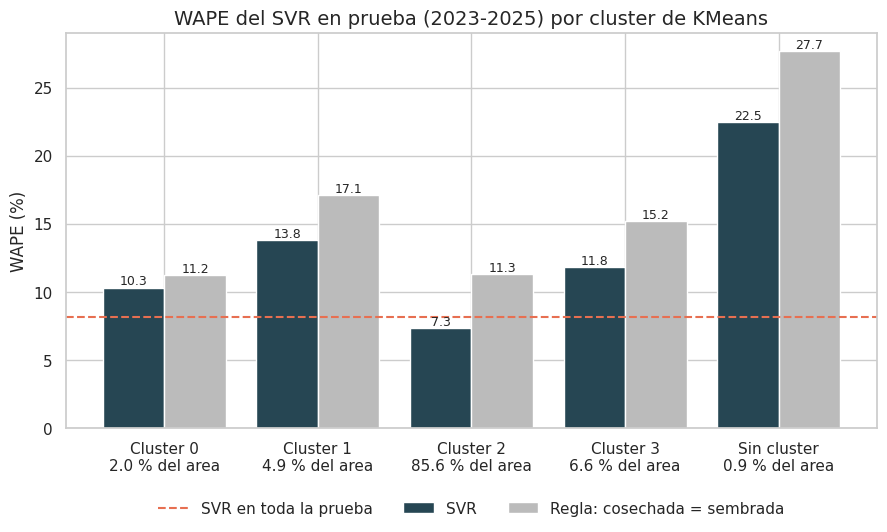

PASO B1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO B1: WAPE del SVR en cada cluster (prueba 2023-2025)
# =========================================================
print("PASO B1: WAPE del SVR en cada cluster")
RUTA_EVA = "/content/drive/MyDrive/EVA/"

clus = pd.read_csv(RUTA_EVA + "Resultados_clustering/clusters_" + NOMBRE_MODELO + ".csv", dtype={"cod_mun": str})
pred = pd.read_csv(RUTA_EVA + "Resultados_modelos/Resultados_modelos/predicciones_SVR.csv", dtype={"cod_mun": str})

# Asignar a cada prediccion el cluster de su serie (municipio + cultivo)
cruce = pred.merge(clus[["cod_mun", "cultivo", "cluster"]], on=["cod_mun", "cultivo"], how="left")

def wape(real, estimada):
    return np.abs(real - estimada).sum() / real.sum() * 100

filas = {}
for c in sorted(clus["cluster"].unique()) + ["Sin cluster"]:
    t = cruce[cruce["cluster"].isna()] if c == "Sin cluster" else cruce[cruce["cluster"] == c]
    if len(t) == 0:
        continue
    nombre = c if c == "Sin cluster" else ("Ruido" if c == -1 else "Cluster " + str(c))
    filas[nombre] = {"filas": len(t),
                     "% del area": t["area_cosechada"].sum() / cruce["area_cosechada"].sum() * 100,
                     "WAPE SVR": wape(t["area_cosechada"], t["area_cosechada_estimada"]),
                     "WAPE regla": wape(t["area_cosechada"], t["area_sembrada"])}
puente = pd.DataFrame(filas).T
puente["filas"] = puente["filas"].astype(int)
total_svr = wape(cruce["area_cosechada"], cruce["area_cosechada_estimada"])
print(puente.round(2).to_string())
print("WAPE del SVR en toda la prueba:", round(total_svr, 2), "%")

# Grafica: WAPE del SVR y de la regla simple en cada cluster
grafica = puente[puente["filas"] >= 100]
x = np.arange(len(grafica))
plt.figure(figsize=(max(9, 1.8 * len(grafica)), 5.5))
b1 = plt.bar(x - 0.2, grafica["WAPE SVR"], 0.4, color="#264653", label="SVR")
b2 = plt.bar(x + 0.2, grafica["WAPE regla"], 0.4, color="#bbbbbb", label="Regla: cosechada = sembrada")
plt.bar_label(b1, fmt="%.1f", fontsize=9)
plt.bar_label(b2, fmt="%.1f", fontsize=9)
plt.axhline(total_svr, color="#e76f51", linestyle="--", label="SVR en toda la prueba")
plt.xticks(x, [n + "\n" + str(round(a, 1)) + " % del area" for n, a in grafica["% del area"].items()])
plt.ylabel("WAPE (%)")
plt.title("WAPE del SVR en prueba (2023-2025) por cluster de " + NOMBRE_MODELO)
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()
print("PASO B1: Ejecutado correctamente")
print("-------------------------------")